<a href="https://colab.research.google.com/github/smg063244/4NI25CS202_DAV_LAB/blob/main/4NI25CS202_EXP_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Exp 10: K means clustering applying K means on a dataset, elbow method to find number of K, visualize

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving House_Price_dataset.csv to House_Price_dataset.csv


In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('/content/House_Price_dataset.csv')
df = df[df['purpose'] == 'For Sale'].copy()
df['Area'] = df['Area Size']
df.loc[df['Area Type'] == 'Kanal', 'Area'] = df['Area Size'] * 20
df = df[(df['Area'] > 0) & (df['price'] > 0)]
df = df[
    (df['Area'] < df['Area'].quantile(0.99)) &
    (df['price'] < df['price'].quantile(0.99))
]
df = df.sample(n=2000, random_state=42).copy()
X = df[['Area', 'price']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Elbow method to find optimal K

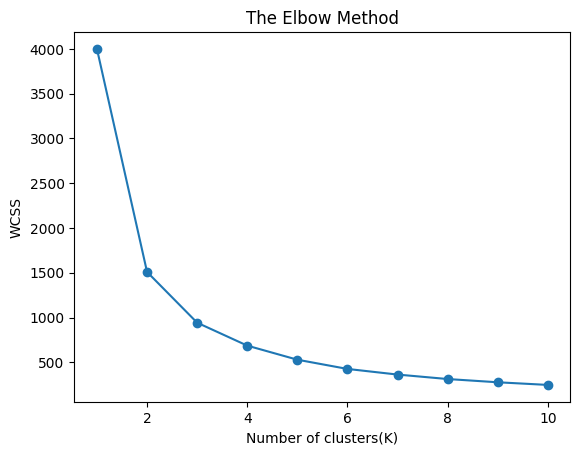

In [ ]:
wcss=[]
for k in range(1,11):
  kmeans=KMeans(n_clusters=k,n_init=10,random_state=42)
  kmeans.fit(X_scaled)
  wcss.append(kmeans.inertia_)
plt.plot(range(1,11),wcss,marker='o')
plt.title('The Elbow Method')
plt.xlabel('Number of clusters(K)')
plt.ylabel('WCSS')
plt.show()

In [ ]:
kmeans=KMeans(n_clusters=3,n_init=10,random_state=42)
df['Cluster']=kmeans.fit_predict(X_scaled)
print(df['Cluster'].value_counts().sort_index())
print(df.groupby('Cluster')[['Area','price']].mean())

Cluster
0    1608
1      88
2     304
Name: count, dtype: int64
              Area         price
Cluster                         
0         6.011007  1.226539e+07
1        28.927273  1.100682e+08
2        18.545066  4.437410e+07


Visualize clusters

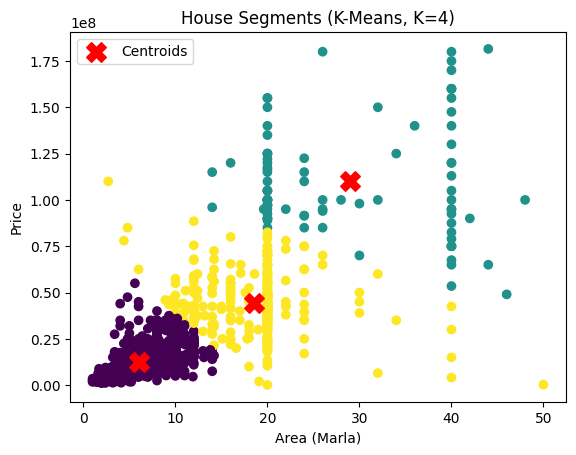

In [ ]:
plt.scatter(df['Area'], df['price'], c=df['Cluster'], cmap='viridis')
centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.xlabel('Area (Marla)'); plt.ylabel('Price')
plt.title('House Segments (K-Means, K=4)'); plt.legend(); plt.show()